In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.stats import mannwhitneyu
import sys
sys.path.append("/glade/work/smagahey/UCSB/codes/paper1_new/paper1/python_packages")

## Parameters

In [2]:
timesfut = ["2070-01", "2099-12"]
timespi  = ["1850-01", "1879-12"]

n34    = [-5,  5, 190, 240]
regbox = [-40, 40,  90, 300]
latlon = [-90, 90,   0, 360]

THRESH_REG = 1.0   # regular ENSO threshold
THRESH_EXT = 2   # extreme ENSO threshold

basedir = '/glade/work/smagahey/UCSB/codes/smile_data/'

models = {
    'E3SMv1':      '/glade/work/smagahey/UCSB/codes/generated_files/tos_1850_2100_E3SMv1LE.nc',
    'E3SMv2':      '/glade/work/smagahey/UCSB/codes/smile_data/tas_-90-90N_0-360E_e3smv2_lens_ssp370.nc',
    'ACCESS':      f'{basedir}tas_{latlon[0]}-{latlon[1]}N_{latlon[2]}-{latlon[3]}E_access_lens_ssp370.nc',
    'CESM2':       f'{basedir}tas_{latlon[0]}-{latlon[1]}N_{latlon[2]}-{latlon[3]}E_cesm2_lens_ssp370.nc',
    'MIROC6':      f'{basedir}tas_{latlon[0]}-{latlon[1]}N_{latlon[2]}-{latlon[3]}E_miroc6_lens_ssp370.nc',
    'MIROC-ESM2L': f'{basedir}tas_{latlon[0]}-{latlon[1]}N_{latlon[2]}-{latlon[3]}E_miroc_esm2l_lens_ssp370.nc',
    'IPSL':        f'{basedir}tas_{latlon[0]}-{latlon[1]}N_{latlon[2]}-{latlon[3]}E_ipsl_cm6a_lens_ssp370.nc',
    'CanESM5':     f'{basedir}tas_{latlon[0]}-{latlon[1]}N_{latlon[2]}-{latlon[3]}E_canesm5_lens_ssp370.nc',
}

## Amplitude function

Returns mean amplitude and raw event values (for Mann-Whitney).  
LN amplitude is returned as a positive value.

In [3]:
def mean_amplitude(tos, n34, times, regbox, ti1, ti2, threshold=1.0):
    """
    Compute mean EN/LN Nino3.4 amplitude for events exceeding threshold sigma.

    Parameters
    ----------
    tos       : SST DataArray, detrended
    n34       : Nino3.4 box [lat_min, lat_max, lon_min, lon_max]
    times     : ['YYYY-MM', 'YYYY-MM'] time slice for anomaly calculation
    regbox    : broader region box
    ti1, ti2  : 'YYYY-MM' strings for amplitude averaging window
    threshold : SD multiplier for event detection (default 1.0)

    Returns
    -------
    mn_en, mn_ln     : scalar mean amplitudes (positive values)
    en_vals, ln_vals : 1D arrays of per-event amplitudes (for significance testing)
    """
    ens_n34 = tos.sel(
        lat=slice(n34[0], n34[1]), lon=slice(n34[2], n34[3]),
        time=slice(times[0], times[1])
    )
    ens_n34_ref = tos.sel(lat=slice(n34[0], n34[1]), lon=slice(n34[2], n34[3]))

    ens_n34 = ens_n34.groupby('time.month') - ens_n34.groupby('time.month').mean()

    def to_djf(da):
        q = da.resample(time='QS-DEC').mean('time')
        return q.where(q.time.dt.month == 12, drop=True)

    ens_n34_djf = to_djf(ens_n34)
    ens_ref_djf = to_djf(
        ens_n34_ref.resample(time='QS-DEC').mean('time')
        .pipe(lambda q: q.where(q.time.dt.month == 12, drop=True))
    )

    n34_std = ens_ref_djf.std('time').mean('member').squeeze()
    msk_en  = ens_n34_djf >  threshold * n34_std
    msk_ln  = ens_n34_djf < -threshold * n34_std

    en_evt = ens_n34_djf.where(msk_en).sel(time=slice(ti1, ti2))
    ln_evt = ens_n34_djf.where(msk_ln).sel(time=slice(ti1, ti2))

    # Pool member x time into 1D, drop nans
    en_vals = en_evt.mean('lat').mean('lon').values.reshape(-1)
    ln_vals = ln_evt.mean('lat').mean('lon').values.reshape(-1)
    en_vals = en_vals[np.isfinite(en_vals)]
    ln_vals = ln_vals[np.isfinite(ln_vals)]

    mn_en =  float(np.mean(en_vals)) if len(en_vals) > 0 else np.nan
    mn_ln = -float(np.mean(ln_vals)) if len(ln_vals) > 0 else np.nan

    return mn_en, mn_ln, en_vals, -ln_vals

## Compute amplitudes and significance for all models

In [4]:
def mwu_p(a, b):
    """Two-sided Mann-Whitney U p-value. NaN if too few events."""
    if len(a) < 3 or len(b) < 3:
        return np.nan
    _, p = mannwhitneyu(a, b, alternative='two-sided')
    return p


rows = []

for model, sst_file in tqdm(models.items()):
    print(f'\nLoading {model}...')

    if model == 'E3SMv1':
        tos = xr.open_dataset(sst_file)['tos']
    elif model == 'E3SMv2':
        tos = xr.open_dataset(sst_file)['tas']
    else:
        ds  = xr.open_dataset(sst_file)
        tos = ds['tas'] if 'tas' in ds else ds['tos']
        tos = tos.drop_duplicates('time')
        tos = tos.convert_calendar('proleptic_gregorian', use_cftime=True, align_on='year')

    tos = tos - tos.mean('member')

    # Regular (1 sigma)
    en_pi_r,  ln_pi_r,  en_pi_r_v,  ln_pi_r_v  = mean_amplitude(tos, n34, timespi,  regbox, timespi[0],  timespi[1],  THRESH_REG)
    en_fut_r, ln_fut_r, en_fut_r_v, ln_fut_r_v = mean_amplitude(tos, n34, timesfut, regbox, timesfut[0], timesfut[1], THRESH_REG)

    # Extreme (1.5 sigma)
    en_pi_e,  ln_pi_e,  en_pi_e_v,  ln_pi_e_v  = mean_amplitude(tos, n34, timespi,  regbox, timespi[0],  timespi[1],  THRESH_EXT)
    en_fut_e, ln_fut_e, en_fut_e_v, ln_fut_e_v = mean_amplitude(tos, n34, timesfut, regbox, timesfut[0], timesfut[1], THRESH_EXT)

    p_en_r = mwu_p(en_pi_r_v, en_fut_r_v)
    p_ln_r = mwu_p(ln_pi_r_v, ln_fut_r_v)
    p_en_e = mwu_p(en_pi_e_v, en_fut_e_v)
    p_ln_e = mwu_p(ln_pi_e_v, ln_fut_e_v)

    rows.append({
        'Model':         model,
        'EN PI (reg)':   en_pi_r,
        'EN FUT (reg)':  en_fut_r,
        'EN % d (reg)':  (en_fut_r - en_pi_r) / en_pi_r * 100,
        'EN p (reg)':    p_en_r,
        'LN PI (reg)':   ln_pi_r,
        'LN FUT (reg)':  ln_fut_r,
        'LN % d (reg)':  (ln_fut_r - ln_pi_r) / ln_pi_r * 100,
        'LN p (reg)':    p_ln_r,
        'EN PI (ext)':   en_pi_e,
        'EN FUT (ext)':  en_fut_e,
        'EN % d (ext)':  (en_fut_e - en_pi_e) / en_pi_e * 100,
        'EN p (ext)':    p_en_e,
        'LN PI (ext)':   ln_pi_e,
        'LN FUT (ext)':  ln_fut_e,
        'LN % d (ext)':  (ln_fut_e - ln_pi_e) / ln_pi_e * 100,
        'LN p (ext)':    p_ln_e,
    })

    print(f'  EN reg: PI={en_pi_r:.3f} FUT={en_fut_r:.3f} ({(en_fut_r-en_pi_r)/en_pi_r*100:+.1f}%) p={p_en_r:.4f}  '
          f'LN reg: PI={ln_pi_r:.3f} FUT={ln_fut_r:.3f} ({(ln_fut_r-ln_pi_r)/ln_pi_r*100:+.1f}%) p={p_ln_r:.4f}')
    print(f'  EN ext: PI={en_pi_e:.3f} FUT={en_fut_e:.3f} ({(en_fut_e-en_pi_e)/en_pi_e*100:+.1f}%) p={p_en_e:.4f}  '
          f'LN ext: PI={ln_pi_e:.3f} FUT={ln_fut_e:.3f} ({(ln_fut_e-ln_pi_e)/ln_pi_e*100:+.1f}%) p={p_ln_e:.4f}')

print('\nDone.')

  0%|          | 0/8 [00:00<?, ?it/s]


Loading E3SMv1...


 12%|█▎        | 1/8 [00:18<02:07, 18.18s/it]

  EN reg: PI=1.482 FUT=1.733 (+16.9%) p=0.0017  LN reg: PI=1.372 FUT=1.728 (+26.0%) p=0.0000
  EN ext: PI=2.309 FUT=2.658 (+15.1%) p=0.0001  LN ext: PI=2.725 FUT=2.594 (-4.8%) p=0.2997

Loading E3SMv2...


 25%|██▌       | 2/8 [00:20<00:52,  8.68s/it]

...

  EN reg: PI=1.521 FUT=1.692 (+11.2%) p=0.0132  LN reg: PI=1.365 FUT=1.589 (+16.4%) p=0.0005
  EN ext: PI=2.492 FUT=2.341 (-6.1%) p=0.4378  LN ext: PI=1.961 FUT=2.387 (+21.7%) p=0.0798

Loading IPSL...


 88%|████████▊ | 7/8 [00:52<00:05,  5.57s/it]

  EN reg: PI=1.205 FUT=1.371 (+13.7%) p=0.0125  LN reg: PI=1.155 FUT=1.236 (+7.0%) p=0.0685
  EN ext: PI=2.045 FUT=2.068 (+1.1%) p=0.9824  LN ext: PI=1.988 FUT=1.964 (-1.2%) p=0.6403

Loading CanESM5...


100%|██████████| 8/8 [01:05<00:00,  8.15s/it]

  EN reg: PI=0.935 FUT=1.070 (+14.4%) p=0.0000  LN reg: PI=0.961 FUT=1.082 (+12.6%) p=0.0000
  EN ext: PI=1.598 FUT=1.765 (+10.4%) p=0.0063  LN ext: PI=1.565 FUT=1.685 (+7.7%) p=0.0044

Done.


## Summary table

* = significant at p < 0.05 (Mann-Whitney U)

In [5]:
df = pd.DataFrame(rows).set_index('Model')

def fmt(val, p):
    star = '*' if (not np.isnan(p) and p < 0.05) else ' '
    return f'{val:+.1f}{star}'

for label, suf in [('Regular events (1 sigma)', 'reg'), ('Extreme events (1.5 sigma)', 'ext')]:
    print(f'=== {label} ===')
    print(f"{'Model':12s}  {'EN PI':>7} {'EN FUT':>7} {'EN % d':>8} {'EN p':>7}    {'LN PI':>7} {'LN FUT':>7} {'LN % d':>8} {'LN p':>7}")
    print('-' * 88)
    for model in models:
        r = df.loc[model]
        print(
            f"{model:12s}  "
            f"{r[f'EN PI ({suf})']:7.3f} {r[f'EN FUT ({suf})']:7.3f} "
            f"{fmt(r[f'EN % d ({suf})'], r[f'EN p ({suf})']):>8} {r[f'EN p ({suf})']:7.4f}    "
            f"{r[f'LN PI ({suf})']:7.3f} {r[f'LN FUT ({suf})']:7.3f} "
            f"{fmt(r[f'LN % d ({suf})'], r[f'LN p ({suf})']):>8} {r[f'LN p ({suf})']:7.4f}"
        )
    print()

=== Regular events (1 sigma) ===
Model           EN PI  EN FUT   EN % d    EN p      LN PI  LN FUT   LN % d    LN p
----------------------------------------------------------------------------------------
E3SMv1          1.482   1.733   +16.9*  0.0017      1.372   1.728   +26.0*  0.0000
E3SMv2          1.329   1.467   +10.3   0.1236      1.377   1.397    +1.5   0.8554
ACCESS          1.245   1.327    +6.6*  0.0034      1.336   1.434    +7.4*  0.0301
CESM2           1.580   1.441    -8.8*  0.0000      1.648   1.724    +4.6*  0.0193
MIROC6          1.147   1.304   +13.7   0.0807      1.046   1.358   +29.9*  0.0184
MIROC-ESM2L     1.521   1.692   +11.2*  0.0132      1.365   1.589   +16.4*  0.0005
IPSL            1.205   1.371   +13.7*  0.0125      1.155   1.236    +7.0   0.0685
CanESM5         0.935   1.070   +14.4*  0.0000      0.961   1.082   +12.6*  0.0000

=== Extreme events (1.5 sigma) ===
Model           EN PI  EN FUT   EN % d    EN p      LN PI  LN FUT   LN % d    LN p
------------

## Plot: % change in amplitude, regular vs extreme

Hatching = p >= 0.05 (Mann-Whitney U)

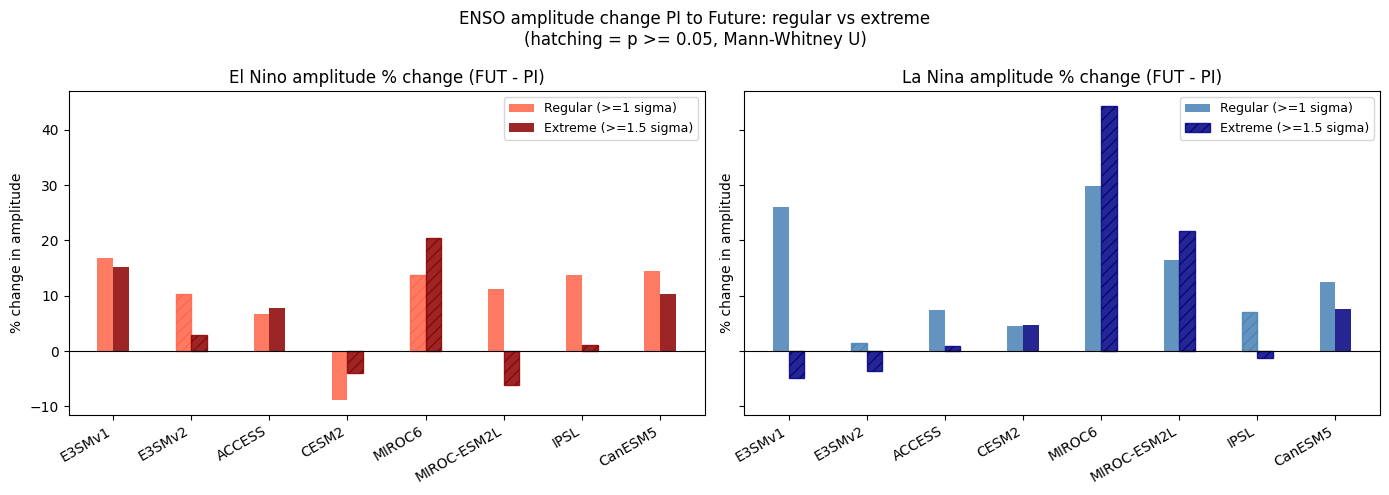

In [6]:
model_names = list(models.keys())
x = np.arange(len(model_names))
width = 0.2

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, event, color_reg, color_ext, title in zip(
    axes,
    ['EN', 'LN'],
    ['tomato',  'steelblue'],
    ['darkred', 'navy'],
    ['El Nino amplitude % change (FUT - PI)',
     'La Nina amplitude % change (FUT - PI)']
):
    reg_vals = df[f'{event} % d (reg)'].values
    ext_vals = df[f'{event} % d (ext)'].values
    p_reg    = df[f'{event} p (reg)'].values
    p_ext    = df[f'{event} p (ext)'].values

    bars_reg = ax.bar(x - width/2, reg_vals, width, label='Regular (>=1 sigma)',   color=color_reg, alpha=0.85)
    bars_ext = ax.bar(x + width/2, ext_vals, width, label='Extreme (>=1.5 sigma)', color=color_ext, alpha=0.85)

    for bar, p in zip(bars_reg, p_reg):
        if np.isnan(p) or p >= 0.05:
            bar.set_hatch('///')
            bar.set_edgecolor(color_reg)
    for bar, p in zip(bars_ext, p_ext):
        if np.isnan(p) or p >= 0.05:
            bar.set_hatch('///')
            bar.set_edgecolor(color_ext)

    ax.axhline(0, color='k', lw=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(model_names, rotation=30, ha='right')
    ax.set_ylabel('% change in amplitude')
    ax.set_title(title)
    ax.legend(fontsize=9)

plt.suptitle('ENSO amplitude change PI to Future: regular vs extreme\n(hatching = p >= 0.05, Mann-Whitney U)', fontsize=12)
plt.tight_layout()
plt.savefig('enso_amplitude_change_reg_vs_ext.png', dpi=150, bbox_inches='tight')
plt.show()

## Save

In [7]:
df.round(4).to_csv('enso_amplitude_table.csv')
print('Saved to enso_amplitude_table.csv')

Saved to enso_amplitude_table.csv
